# What Does the Azerbaijani Job Market Want from Data Analysts?

**Question:** Which skills, experience levels and employers dominate data and analytics vacancies in Azerbaijan right now?
I am a data analytics student, and I want my learning plan to follow real demand instead of guesswork.

**Data:** vacancies scraped from [hellojob.az](https://www.hellojob.az) on **23 November 2026** (snapshot) with `src/scraper.py`.
171 pages matched data-related searches. After filtering by job title, **35 are data and analytics roles**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
IMAGES = ROOT / "images"
BLUE, BLUE_LIGHT, ORANGE, INK_2, MUTED, GRID, SURFACE = "#2a78d6", "#9ec5f4", "#eb6834", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.labelcolor": INK_2, "savefig.dpi": 150, "savefig.bbox": "tight",
})

df = pd.read_csv(ROOT / "data" / "processed" / "data_roles.csv")
summary = json.loads((ROOT / "data" / "processed" / "summary.json").read_text())
SKILLS = df.columns[df.columns.get_loc("SQL"):df.columns.get_loc("Russian") + 1].tolist()
print(summary)
df[["title", "company", "role_family", "seniority", "min_experience_years"]]

{'snapshot': '2026-11-23', 'vacancies_scraped': 171, 'data_roles': 35, 'salary_disclosed_all': 5}


,title,company,role_family,seniority,min_experience_years
0,Biznes analitik (Mobil tətbiqlər üzrə),Kontakt Home,Business Analyst,Junior / Mid,1.0
1,Maliyyə hesabatlığı və təhlil şöbəsinin mütəxə...,ABB,Reporting / Financial Analyst,Junior / Mid,3.0
2,"Tələblər üzrə aparıcı analitik, Gəlirlərin ida...",Azərbaycan Hava Yolları,Data Analyst,Senior,2.0
3,IT Biznes Analitik (Elektron Kommersiya),Kontakt Home,Business Analyst,Junior / Mid,1.0
4,Data idarəçiliyi şöbəsinin müdiri,İnnovasiya və Rəqəmsal İnkişaf Agentliyi,Data Engineering / Governance,Lead / Head,3.0
5,Data Arxitektor,İnnovasiya və Rəqəmsal İnkişaf Agentliyi,Data Engineering / Governance,Junior / Mid,5.0
6,Data elmi üzrə ekspert - Mikro biznes departam...,Kapital Bank,Data Science / AI,Senior,NaN
7,Data elmi üzrə ekspert - Analitika və Aİ ekspe...,Kapital Bank,Data Science / AI,Senior,NaN
8,"QSS Analytics Təcrübə Proqramı - Data Science,...",QSS Analytics,Data Science / AI,Intern,NaN
9,Senior Data Analyst,PASHA Life,Data Analyst,Senior,3.0


## 1. Which skills are asked for most?

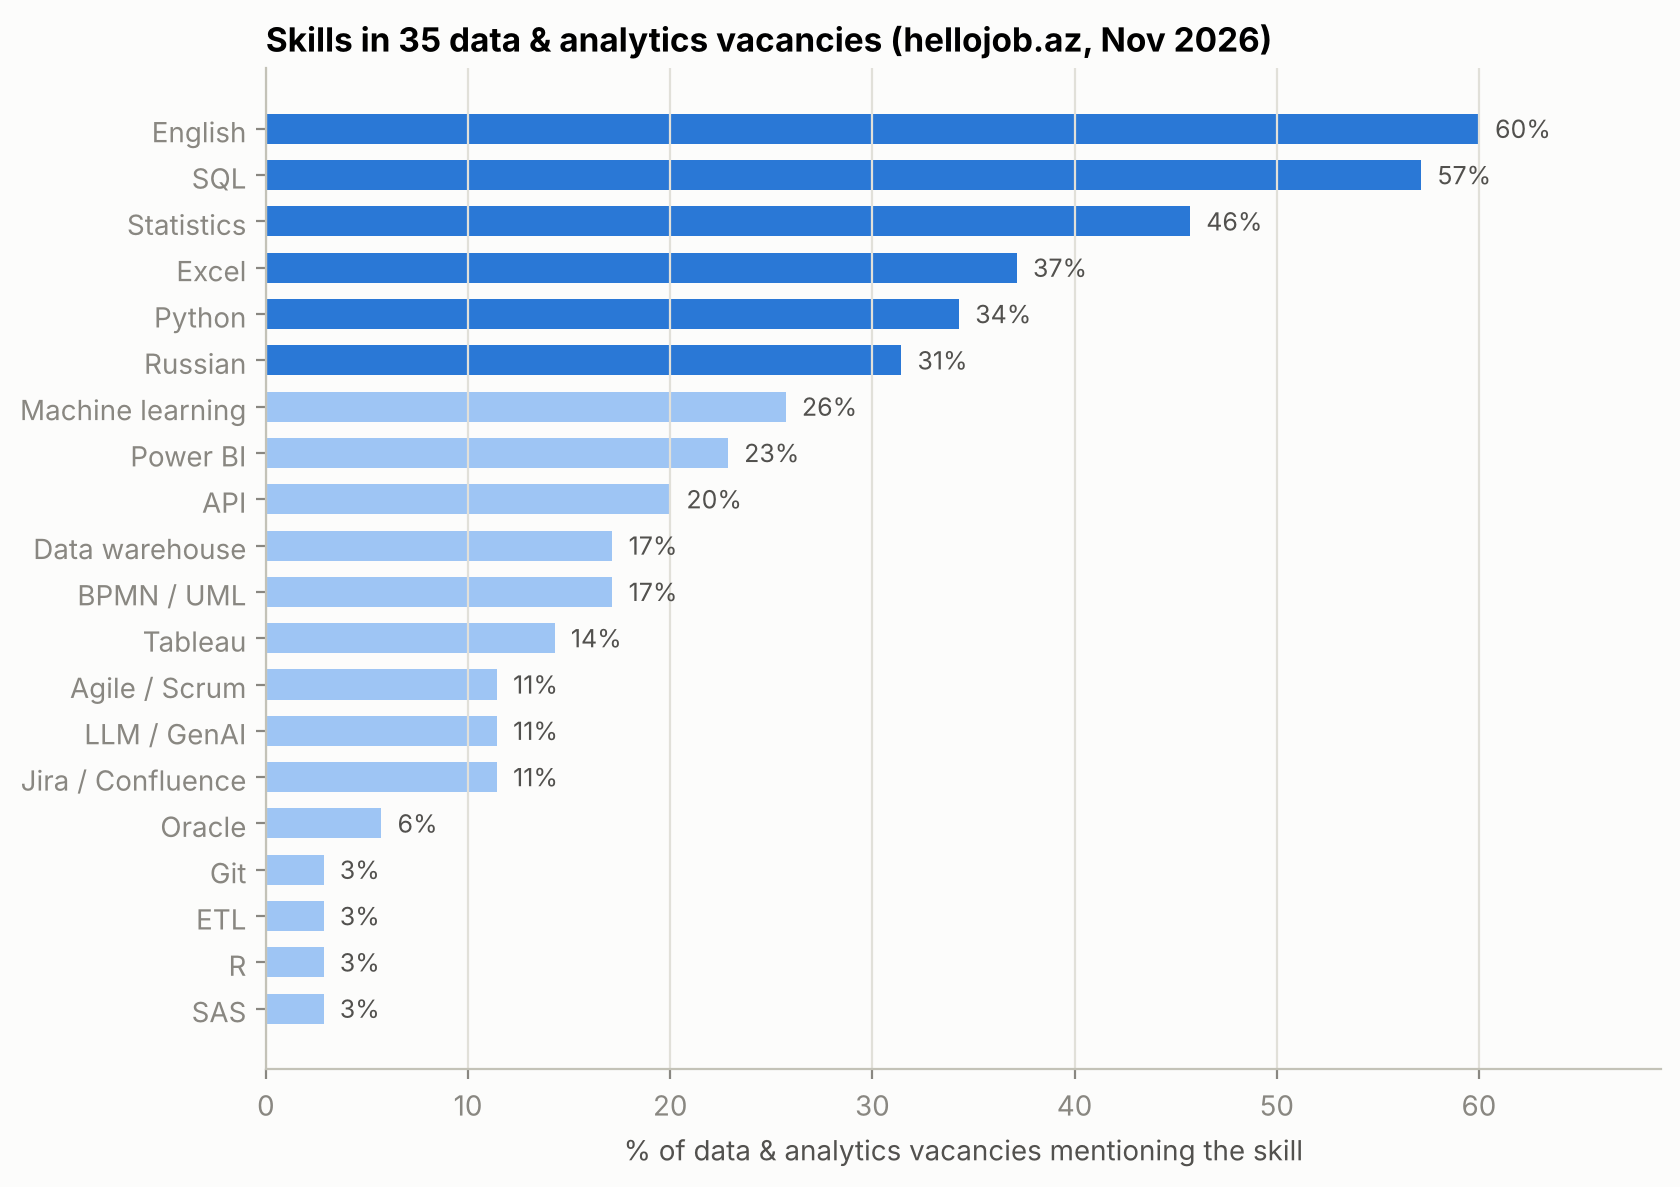

English              60.0
SQL                  57.1
Statistics           45.7
Excel                37.1
Python               34.3
Russian              31.4
Machine learning     25.7
Power BI             22.9
API                  20.0
BPMN / UML           17.1
Data warehouse       17.1
Tableau              14.3
Agile / Scrum        11.4
Jira / Confluence    11.4
LLM / GenAI          11.4
Oracle                5.7
Git                   2.9
ETL                   2.9
R                     2.9
SAS                   2.9
dtype: float64

In [2]:
skill_share = df[SKILLS].mean().sort_values() * 100
skill_share = skill_share[skill_share > 0]

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = [BLUE if s >= 30 else BLUE_LIGHT for s in skill_share]
ax.barh(skill_share.index, skill_share.values, color=colors, height=0.65)
for i, v in enumerate(skill_share.values):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9, color=INK_2)
ax.set_xlabel("% of data & analytics vacancies mentioning the skill")
ax.set_xlim(0, skill_share.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title(f"Skills in {len(df)} data & analytics vacancies (hellojob.az, Nov 2026)")
fig.savefig(IMAGES / "top_skills.png"); plt.show()
skill_share.sort_values(ascending=False).round(1)

## 2. Skills differ by role

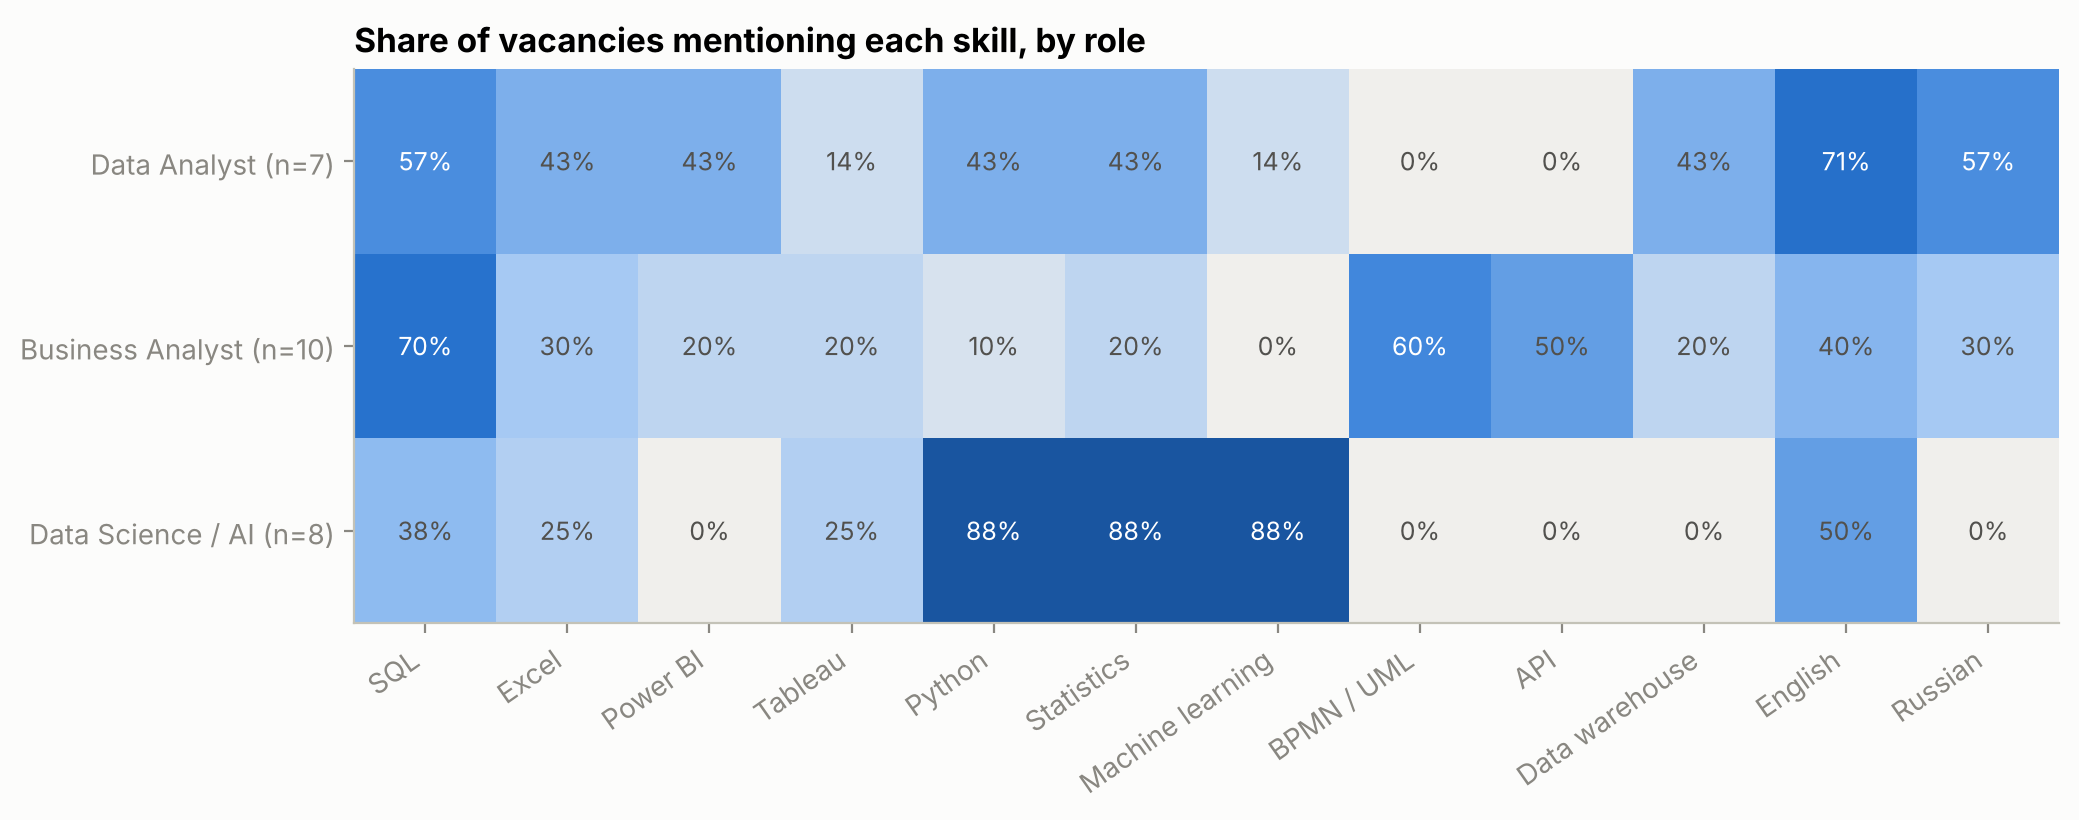

,SQL,Excel,Power BI,Tableau,Python,Statistics,Machine learning,BPMN / UML,API,Data warehouse,English,Russian
role_family,,,,,,,,,,,,
Data Analyst,57.0,43.0,43.0,14.0,43.0,43.0,14.0,0.0,0.0,43.0,71.0,57.0
Business Analyst,70.0,30.0,20.0,20.0,10.0,20.0,0.0,60.0,50.0,20.0,40.0,30.0
Data Science / AI,38.0,25.0,0.0,25.0,88.0,88.0,88.0,0.0,0.0,0.0,50.0,0.0


In [3]:
families = ["Data Analyst", "Business Analyst", "Data Science / AI"]
focus = ["SQL", "Excel", "Power BI", "Tableau", "Python", "Statistics", "Machine learning",
         "BPMN / UML", "API", "Data warehouse", "English", "Russian"]
by_role = (df[df["role_family"].isin(families)].groupby("role_family")[focus].mean() * 100).reindex(families)
counts = df["role_family"].value_counts()

fig, ax = plt.subplots(figsize=(11, 3.6))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])
ax.imshow(by_role.values, cmap=cmap, aspect="auto", vmin=0, vmax=100)
for (i, j), v in np.ndenumerate(by_role.values):
    ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if v > 55 else INK_2)
ax.set_xticks(range(len(focus)), focus, rotation=35, ha="right")
ax.set_yticks(range(len(families)), [f"{f} (n={counts[f]})" for f in families])
ax.grid(False)
ax.set_title("Share of vacancies mentioning each skill, by role")
fig.savefig(IMAGES / "skills_by_role.png"); plt.show()
by_role.round(0)

## 3. Who is hiring?

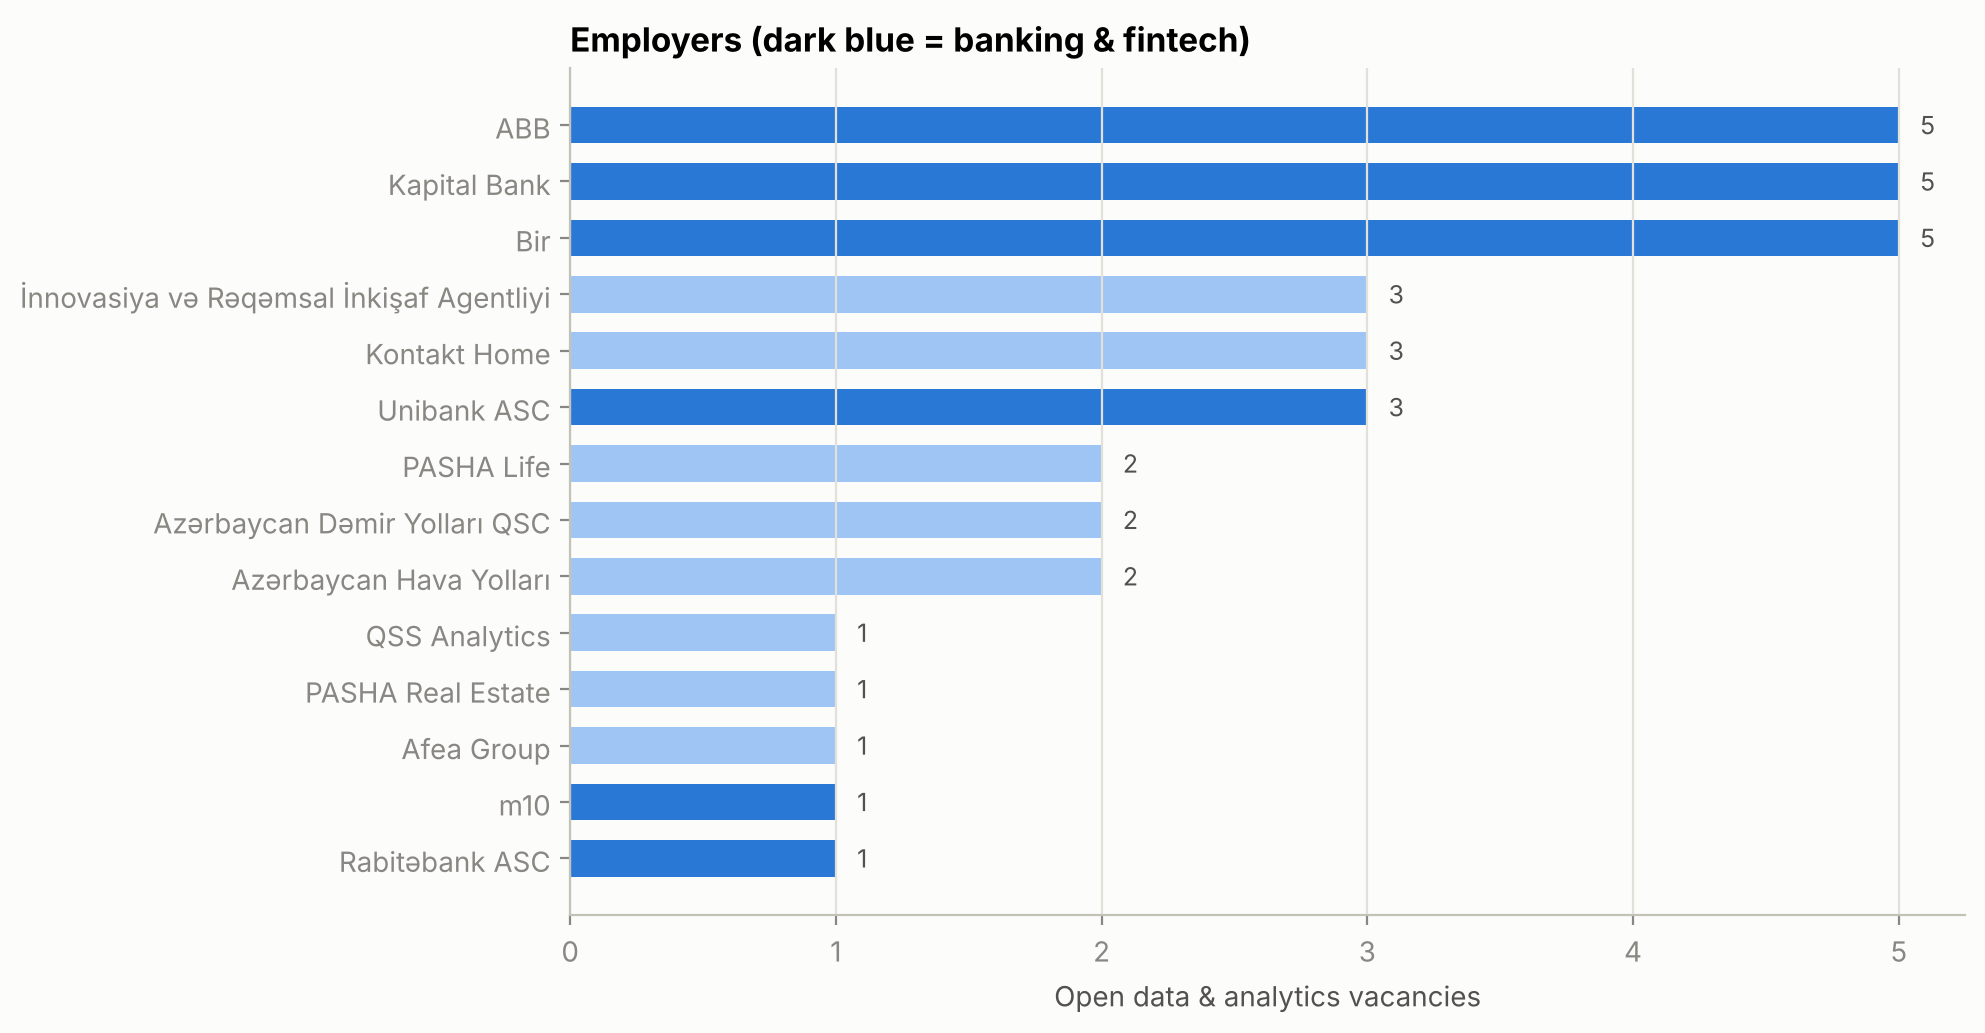

sector
Banking & fintech    57.0
Transport            11.0
Retail                9.0
Government            9.0
IT & consulting       6.0
Insurance             6.0
Real estate           3.0
Name: proportion, dtype: float64

In [4]:
SECTOR = {
    "ABB": "Banking & fintech", "Kapital Bank": "Banking & fintech", "Bir": "Banking & fintech",
    "Unibank ASC": "Banking & fintech", "Rabitəbank ASC": "Banking & fintech", "m10": "Banking & fintech",
    "İnnovasiya və Rəqəmsal İnkişaf Agentliyi": "Government", "Kontakt Home": "Retail",
    "Azərbaycan Hava Yolları": "Transport", "Azərbaycan Dəmir Yolları QSC": "Transport",
    "PASHA Life": "Insurance", "PASHA Real Estate": "Real estate",
    "QSS Analytics": "IT & consulting", "Afea Group": "IT & consulting",
}
df["sector"] = df["company"].map(SECTOR).fillna("Other")

companies = df["company"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [BLUE if SECTOR.get(c) == "Banking & fintech" else BLUE_LIGHT for c in companies.index]
ax.barh(companies.index, companies.values, color=colors, height=0.65)
for i, v in enumerate(companies.values):
    ax.text(v + 0.08, i, str(v), va="center", fontsize=9, color=INK_2)
ax.set_xlabel("Open data & analytics vacancies")
ax.grid(axis="y", visible=False)
ax.set_title("Employers (dark blue = banking & fintech)")
fig.savefig(IMAGES / "top_employers.png"); plt.show()
(df["sector"].value_counts(normalize=True) * 100).round(0)

## 4. How much experience do employers expect?

Vacancies stating a minimum: 25 of 35
Median minimum experience: 2 years


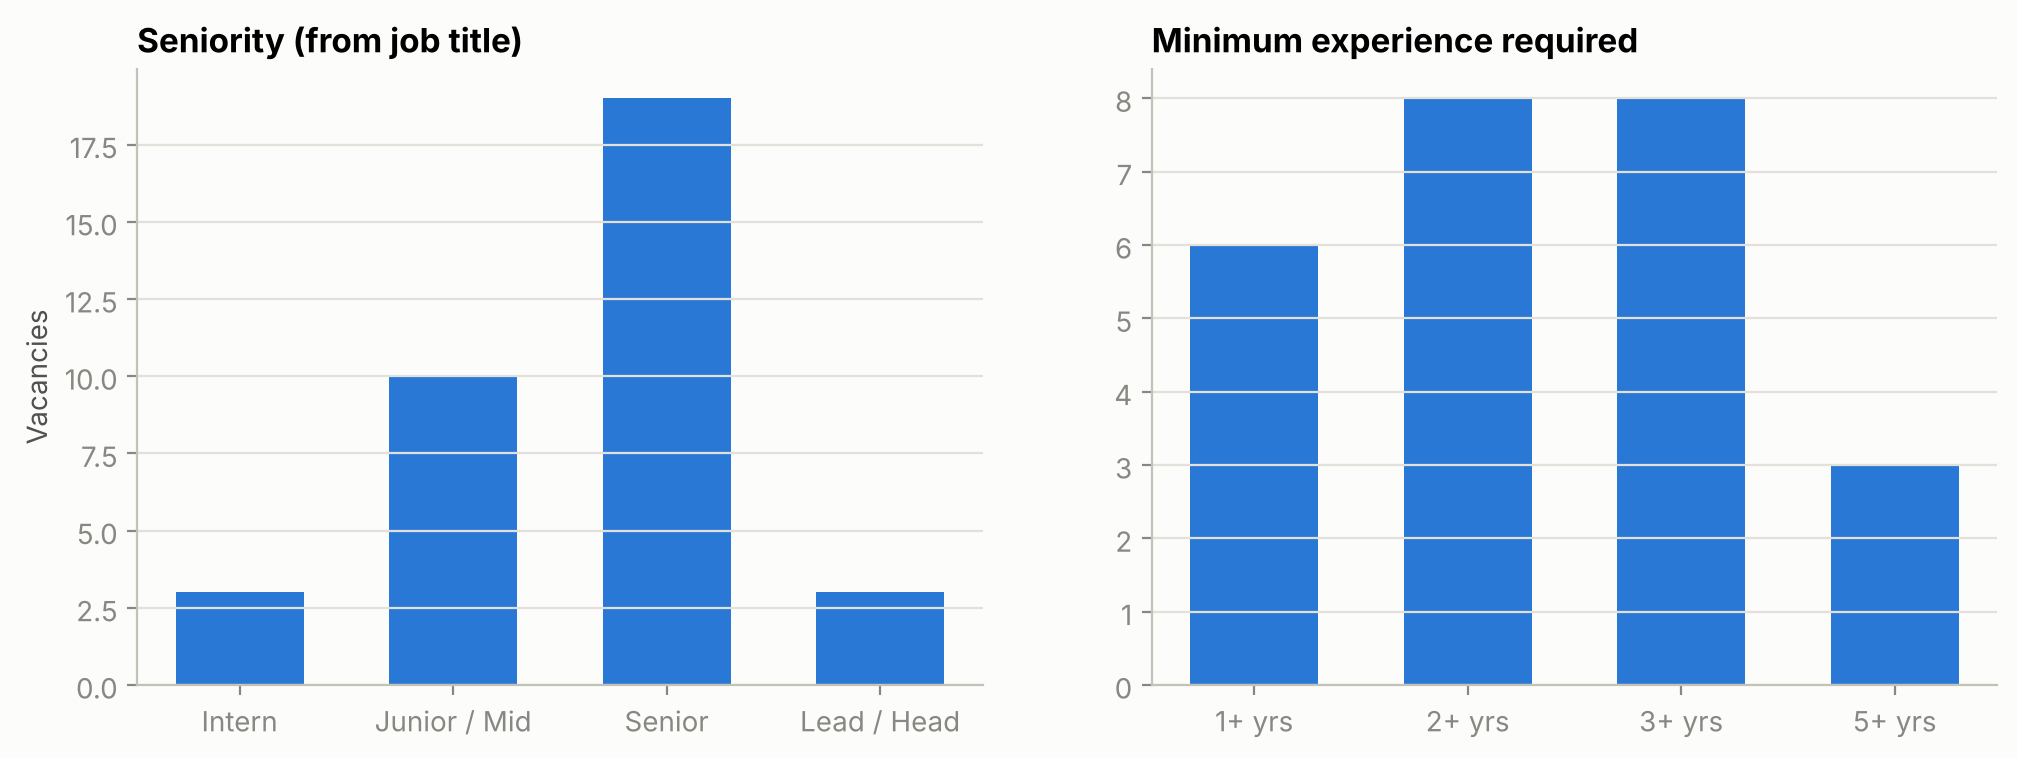

In [5]:
exp = df["min_experience_years"]
print(f"Vacancies stating a minimum: {exp.notna().sum()} of {len(df)}")
print(f"Median minimum experience: {exp.median():.0f} years")

order = ["Intern", "Junior / Mid", "Senior", "Lead / Head"]
seniority = df["seniority"].value_counts().reindex(order)
exp_counts = exp.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(seniority.index, seniority.values, color=BLUE, width=0.6)
axes[0].set_title("Seniority (from job title)")
axes[0].set_ylabel("Vacancies")
axes[1].bar(exp_counts.index.astype(int).astype(str) + "+ yrs", exp_counts.values, color=BLUE, width=0.6)
axes[1].set_title("Minimum experience required")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.savefig(IMAGES / "experience.png"); plt.show()

## 5. Salary transparency

In [6]:
print(f"Data roles with a published salary: {df['salary_disclosed'].sum()} of {len(df)}")
print(f"All scraped vacancies with a published salary: {summary['salary_disclosed_all']} of {summary['vacancies_scraped']}")

Data roles with a published salary: 0 of 35
All scraped vacancies with a published salary: 5 of 171


## 6. Conclusions: what this means for a student entering the field

1. **SQL is the core technical skill.** It appears in 57% of data vacancies, more than any other tool, and in 70% of Business Analyst roles.
2. **English matters as much as SQL** (60% of vacancies). Russian is asked for in about a third.
3. **Power BI beats Tableau** (23% vs 14%), so it is the better BI tool to learn first for this market.
4. **Python and statistics separate analysts from report builders.** Statistics appears in 46% of vacancies and Python in 34%. Both are near-universal in Data Science roles.
5. **Banking and fintech dominate.** 57% of vacancies come from banks and fintechs (ABB, Kapital Bank, Bir, Unibank). Domain knowledge of banking products, risk and CRM is a real advantage.
6. **The entry barrier is experience, not tools.** More than half the roles are senior-titled, and the typical minimum is 2 years. Internship programs (Kapital Bank, Rabitəbank, QSS Analytics) are the realistic entry point.
7. **Salaries are almost never published.** 0 of 35 data roles show a salary, so salary research has to come from other sources.

**My learning priorities from this data:** SQL (advanced: window functions, CTEs) → Power BI + Excel → Python (pandas) + statistics → English for technical interviews → banking-domain projects.

**Limitations:** a single job board, a single snapshot, and n = 35. Skill detection is keyword-based (Azerbaijani + English) and can miss synonyms.
Re-running `src/scraper.py` monthly would turn this into a trend analysis.